[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/timecorr/blob/master/docs/tutorial/htfa_network_animations.ipynb)

# Brain-network animations of orders 1 to 4 (with HTFA)

This notebook computes features of orders 1 to 4 with `tc.features` on fMRI data recorded while people listened to a story, works out which brain locations each order's features belong to, and draws them on the brain over time with the plotting functions of the [htfa](https://htfa.readthedocs.io/en/latest/) toolbox.

**Data.** The intact condition of the story-listening dataset of Simony et al. (2016), "Dynamic reconfiguration of the default mode network during narrative comprehension", *Nature Communications* 7, 12141 ([doi:10.1038/ncomms12141](https://doi.org/10.1038/ncomms12141); images: [doi:10.34770/nvet-9850](https://doi.org/10.34770/nvet-9850)), as analyzed by Owen, Chang & Manning (2021), "High-level cognition during story listening is reflected in high-order dynamic correlations in neural activity patterns", *Nature Communications* 12, 5728 ([doi:10.1038/s41467-021-25876-x](https://doi.org/10.1038/s41467-021-25876-x)). Owen et al. applied hierarchical topographic factor analysis (HTFA; Manning et al., 2018, "A probabilistic approach to discovering dynamic full-brain functional connectivity patterns", *NeuroImage* 180, 243-252, [doi:10.1016/j.neuroimage.2018.01.071](https://doi.org/10.1016/j.neuroimage.2018.01.071)) to the images. HTFA describes each image as a weighted sum of 700 nodes (radial basis functions, each with a center and a width); the nodes of each participant are matched to a global template, so node `i` is the same node in every participant. The analyses of Owen et al. used each participant's matrix of node weights (timepoints by 700 nodes). The fit, with the node weights of every participant, is in the data archive of the paper's repository, [github.com/ContextLab/timecorr-paper](https://github.com/ContextLab/timecorr-paper), which this notebook downloads.

Sections:

1. downloading and loading the HTFA fit;
2. choosing the nodes to analyze;
3. features of orders 1 to 4 with the defaults of `tc.features`, and what each step did;
4. which nodes each order's features belong to;
5. the animations.

The archive is 460 MB; the notebook keeps the fit (233 MB) in a cache folder and deletes the archive. The `TIMECORR_DATA` environment variable sets the folder (default: `~/timecorr_data`). The run time of each step is printed below.

In [1]:
# On Google Colab, install timecorr and htfa (this cell does nothing elsewhere).
# It installs timecorr 0.3.0 or later from PyPI; if that release is not on PyPI yet,
# it installs from GitHub instead. Colab may ask you to restart the runtime after
# installing; if it does, restart it and run all cells again.
import sys
if "google.colab" in sys.modules:
    !pip install -q "htfa[plot,brain3d]>=0.1.0"
    !pip install -q "timecorr>=0.3.0" 2>/dev/null || pip install -q "git+https://github.com/ContextLab/timecorr.git@master"

In [2]:
import hashlib
import os
import time
import urllib.request
import warnings
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import scipy.io
import io

from IPython.display import Image, Video, display

import htfa
from htfa.brainnet import (
    annotate_pair,
    effective_nodes,
    mni_mask,
    montage,
    plot_network,
    write_animation,
)
import timecorr as tc

%matplotlib inline
plt.rcParams['figure.dpi'] = 72
print('timecorr', tc.__version__, '| htfa', htfa.__version__)

timecorr 0.3.0 | htfa 0.1.0


## 1. Downloading and loading the HTFA fit

The archive `data.zip` linked from the README of the paper's repository (a public Google Drive file) holds `data/pieman_posterior_K700.mat`, the HTFA fit. The cell below downloads the archive once, extracts that file, checks its SHA-256 checksum and deletes the archive.

In [3]:
DATA_DIR = Path(os.environ.get('TIMECORR_DATA', Path.home() / 'timecorr_data')) / 'pieman'
DATA_DIR.mkdir(parents=True, exist_ok=True)
ARCHIVE_URL = ('https://drive.usercontent.google.com/download'
               '?id=1CZYe8eyAkZFuLqfwwlKoeijgkjdW6vFs&export=download&confirm=t')
MEMBER = 'data/pieman_posterior_K700.mat'
FIT_SHA256 = '870179316f127776ff78096c361df6b1c5c7957d6456deb26b5489bcee6c0793'
fit_path = DATA_DIR / 'pieman_posterior_K700.mat'


def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()


if not fit_path.exists():
    archive = DATA_DIR / 'data.zip'
    start = time.time()
    urllib.request.urlretrieve(ARCHIVE_URL, archive)
    with zipfile.ZipFile(archive) as z, z.open(MEMBER) as src, open(fit_path, 'wb') as dst:
        while chunk := src.read(1 << 20):
            dst.write(chunk)
    archive.unlink()
    print(f'downloaded and extracted in {time.time() - start:.0f} s')
if sha256(fit_path) != FIT_SHA256:
    raise RuntimeError(f'{fit_path} does not match its checksum; delete it and run this cell again')
print(fit_path.name, f'{fit_path.stat().st_size / 1e6:.0f} MB')

pieman_posterior_K700.mat 233 MB


The file is a MATLAB structure written by an earlier implementation of HTFA. `htfa.load` reads fits saved by the htfa toolbox itself, not this format, so the cell below reads it with `scipy.io.loadmat`. The structure holds the global template (`centers['mean']`, node centers in MNI millimeters, and `widths['mean']`) and, for every scan, its own centers, widths and node weights (`image_weights['mean']`, timepoints by nodes). A node's spatial profile is `exp(-||r - c||**2 / w)` for a center `c` and width `w`, the same convention as htfa's RBF nodes. Scan names start with the condition (`intact`, `paragraph`, `word` or `resting`); this notebook uses the intact condition.

In [4]:
start = time.time()
post = scipy.io.loadmat(fit_path)['posterior'][0, 0]
names = [str(n[0]) for n in post['subjects_names'][0]]
centers = np.asarray(post['centers'][0, 0]['mean'], dtype=float)           # (700, 3)
widths = np.asarray(post['widths'][0, 0]['mean'], dtype=float).ravel()     # (700,)

intact = sorted((i for i, n in enumerate(names) if n.startswith('intact_')),
                key=lambda i: int(names[i].split('_s')[1].split('.')[0]))
weights = np.stack([post['subjects'][0, i]['image_weights'][0, 0]['mean'][0, 0] for i in intact])
del post
conditions = sorted({n.split('_')[0] for n in names})
print(f'loaded in {time.time() - start:.1f} s')
print('scans per condition:', {c: sum(n.startswith(c + '_') for n in names) for c in conditions})
print('template centers', centers.shape, '| widths', widths.shape,
      f'(from {widths.min():.1f} to {widths.max():.1f})')
print('intact node weights (participants, timepoints, nodes):', weights.shape)

loaded in 0.1 s
scans per condition: {'intact': 36, 'paragraph': 18, 'resting': 36, 'word': 36}
template centers (700, 3) | widths (700,) (from 31.7 to 67.4)
intact node weights (participants, timepoints, nodes): (36, 300, 700)


The template's 700 nodes, drawn with `htfa.plot_network` (BrainNet Viewer style; by default each node is drawn as the part of its RBF that lies inside an MNI brain mask, with sizes set by the widths):

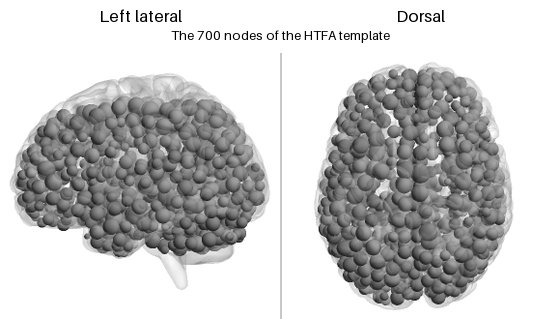

7 s


In [5]:
start = time.time()
VIEW_SIZE = (440, 275)


def show_image(img):
    # embed a PIL image as a JPEG (smaller than PNG)
    buf = io.BytesIO()
    img.convert('RGB').save(buf, format='JPEG', quality=85)
    display(Image(data=buf.getvalue(), format='jpeg'))


all_left = plot_network(centers, widths=widths, size=VIEW_SIZE, view='left')
all_top = plot_network(centers, widths=widths, size=VIEW_SIZE, view='dorsal')
show_image(annotate_pair(all_left, all_top, ('Left lateral', 'Dorsal'),
                         caption='The 700 nodes of the HTFA template', width=560))
print(f'{time.time() - start:.0f} s')

## 2. Choosing the nodes to analyze

Two things limit the nodes used here.

**Constant node weights.** In some participants, a few nodes have weights that are constant over the scan (standard deviation below `1e-6`, against a median of about 1 over all participants and nodes). Their correlations with other nodes are undefined in those participants, so those nodes are left out.

**The default feeding reducer.** With the defaults, the feeding path of `tc.features` summarizes each order with `Communities()`, whose number of communities is counted with a shift null: every feature of a participant is circularly shifted by its own lag, and the lags of one participant must be distinct integers in `[L, T - L]`. With `T = 300` and the default feeding kernel (standard deviation 5 samples), `L = min(T // 4, max(10, 10 * 5)) = 50`, so at most `T - 2L + 1 = 201` features can enter a feeding step; with more, `tc.features` raises `ValueError`.

This notebook uses 100 nodes, to keep the run time to a few minutes. They are chosen by farthest-point sampling of the template centers (start at the node nearest the centroid of all centers; then repeatedly add the node farthest from those already chosen), which spreads them over the brain. The node weights are not changed.

In [6]:
sd = weights.std(axis=1)                       # (participants, nodes)
constant = sd < 1e-6
print(f'median standard deviation of the node weights: {np.median(sd):.2f}')
print(f'(participant, node) pairs with constant weights: {constant.sum()} '
      f'({constant.any(axis=1).sum()} participants, {constant.any(axis=0).sum()} nodes)')
usable = np.flatnonzero(~constant.any(axis=0))

T = weights.shape[1]
L = min(T // 4, max(10, 10 * 5))
print(f'T = {T}, L = {L}: at most {T - 2 * L + 1} features per default feeding step')


def farthest_points(points, k):
    chosen = [int(np.argmin(np.linalg.norm(points - points.mean(axis=0), axis=1)))]
    dist = np.linalg.norm(points - points[chosen[0]], axis=1)
    for _ in range(k - 1):
        chosen.append(int(np.argmax(dist)))
        dist = np.minimum(dist, np.linalg.norm(points - points[chosen[-1]], axis=1))
    return np.array(chosen)


K = 100
nodes = usable[farthest_points(centers[usable], K)]
data = [w[:, nodes] for w in weights]          # one (300, 100) matrix per participant
print(f'{len(usable)} usable nodes; analyzing {K} of them in {len(data)} participants,',
      f'each {data[0].shape[0]} timepoints by {data[0].shape[1]} nodes')

median standard deviation of the node weights: 1.09
(participant, node) pairs with constant weights: 37 (33 participants, 21 nodes)
T = 300, L = 50: at most 201 features per default feeding step
679 usable nodes; analyzing 100 of them in 36 participants, each 300 timepoints by 100 nodes


For drawing, `htfa.brainnet.effective_nodes` moves each chosen node to the part of its RBF inside the MNI brain mask (the same "snapping" `plot_network` does by default). It is computed once here, and the plots below draw these positions as they are (`snap=False`).

median distance moved: 0.4 mm (largest 2.1 mm)


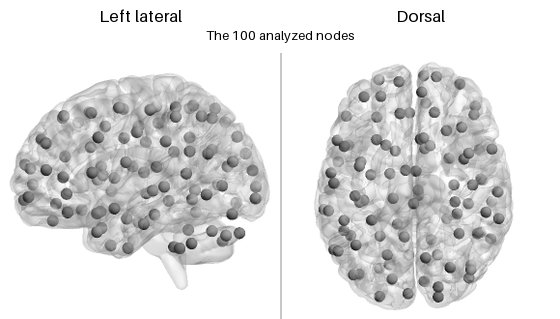

In [7]:
xyz, _, snap_info = effective_nodes(centers[nodes], widths[nodes], mni_mask())
print(f'median distance moved: {np.median(snap_info["distance"]):.1f} mm '
      f'(largest {snap_info["distance"].max():.1f} mm)')
show_image(annotate_pair(plot_network(xyz, snap=False, size=VIEW_SIZE, view='left'),
                      plot_network(xyz, snap=False, size=VIEW_SIZE, view='dorsal'),
                         ('Left lateral', 'Dorsal'), caption=f'The {K} analyzed nodes', width=560))

## 3. Features of orders 1 to 4

`tc.features(data, order=4, return_info=True)` with every other argument at its default computes, for each order `k` from 1 to 4 (see the [higher-order tutorial](higher_order_tutorial.ipynb) and the docstring of `tc.features`):

- the **analysis path**: `X[k]`, the dynamic correlations of the order-`(k-1)` feeding features `D[k-1]` (`D[0]` is the node weights), computed with a Gaussian kernel (variance 100, the default of `gaussian_weights`) and `cfun=tc.isfc` (each participant's features correlated with the mean of the other participants'), kept separate per participant (`combine=tc.null_combine`) and reduced: with PCA at order 1 and with `WeightedStrength(signed=True)` at orders 2 and above (for each input feature `i`, a magnitude column `c_i(t) = sum_j a_ij r_ij(t)**2` and a signed column `s_i(t) = sum_j mean_t(r_ij) r_ij(t)`, where the pair weights `a_ij` are the time-averaged squared correlations minus their median, clipped at 0);
- the **feeding path**: `D[k]`, within-participant dynamic correlations of `D[k-1]` (`autofc`) with a Gaussian kernel of variance 25, reduced with `Communities()` (one column per community of features: the mean squared correlation within it), or, when the communities would give fewer than 4 columns, with `WeightedStrength(split=False, signed=False, center=False)` (one column per input feature). The feeding step of order 4 is not computed, because no later order uses it.

`return_info=True` returns a record of each step: the reducer requested and the one used, the widths, and for the default feeding steps the number of communities and whether the fallback was used.

In [8]:
start = time.time()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    X, info = tc.features(data, order=4, return_info=True)
print(f'tc.features: {time.time() - start:.0f} s')
for w in caught:
    print(f'{w.category.__name__}: {w.message}')
print()
print(f'{"order":>5} {"path":>9} {"input":>6} {"output":>7}  reducer used (fallback)')
for step in info:
    fallback = step.get('fallback')
    extra = '' if fallback is None else f'  (fallback: {fallback}; community columns: {step["n_communities"]})'
    print(f'{step["order"]:>5} {step["path"]:>9} {step["input_width"]:>6} {step["output_width"]:>7}  '
          f'{step["effective"]}{extra}')
print()
for k in range(1, 5):
    print(f'X[{k}]: {len(X[k])} participants x {X[k][0].shape}')

tc.features: 62 s

order      path  input  output  reducer used (fallback)
    1  analysis    100     100  PCA
    1   feeding    100     100  WeightedStrength(split=False, signed=False, n=None, n_null=5, center=False)  (fallback: too_few_community_columns; community columns: 2)
    2  analysis    100     200  WeightedStrength(split=False, signed=True, n=None, n_null=5, center=True)
    2   feeding    100       4  Communities(n=None, signed=False, n_null=5)
    3  analysis      4       8  WeightedStrength(split=False, signed=True, n=None, n_null=5, center=True)
    3   feeding      4       4  WeightedStrength(split=False, signed=False, n=None, n_null=5, center=False)  (fallback: too_few_community_columns; community columns: 1)
    4  analysis      4       8  WeightedStrength(split=False, signed=True, n=None, n_null=5, center=True)

X[1]: 36 participants x (300, 100)
X[2]: 36 participants x (300, 200)
X[3]: 36 participants x (300, 8)
X[4]: 36 participants x (300, 8)


What the record shows for this run:

- **Order 1, feeding.** The communities of the 100 node features would have emitted 2 columns, fewer than 4, so the step used the fallback `WeightedStrength(split=False, signed=False, center=False)` (`fallback: too_few_community_columns`): `D[1]` has one column per node.
- **Order 2, feeding.** The communities emitted 4 columns, so the step used `Communities()`: `D[2]` has one column per community, and `X[3]` and `X[4]` have 8 columns each (4 magnitude and 4 signed columns).
- **Order 3, feeding.** The communities of the 4 columns of `D[2]` would have emitted 1 column, so the step used the fallback: `D[3]` has one column per column of `D[2]`.
- **Warnings.** The two `UserWarning`s come from `WeightedStrength` steps (the message does not name the step): 8 and 13 output columns are constant over time and were set to their means. The warning gives, as one possible cause, that every weight of a column is 0.

## 4. Which nodes each order's features belong to

A picture on the brain needs, for every value drawn, a set of nodes it belongs to.

- **Order 1.** `X[1]` is a PCA of the vectorized node-by-node correlations. Each PCA component mixes all 4,950 node pairs, so it has no location of its own, and `X[1]` is not drawn. Instead, the order-1 animation draws the node-by-node correlations that `X[1]` reduces, `tc.timecorr(data, cfun=tc.isfc)` with the same (default) kernel, averaged over participants with `tc.corrmean_combine`, as edges between the nodes.
- **Orders 2 and above.** Column `i` of a `WeightedStrength` output belongs to input feature `i` of that step, which is column `i` of the feeding features `D[k-1]`. Each feeding column in turn belongs to a set of nodes: at `D[0]`, column `i` is node `i`; a `WeightedStrength` feeding step keeps one column per input feature, so its columns belong to the same sets as its inputs; a `Communities` feeding step emits one column per community with at least 2 members (in order of the community's smallest member), which belongs to the union of its members' sets. Features in communities of a single member emit no column, so their nodes are not represented at later orders.

The default reducers (`"auto"`) are created inside `tc.features`, so their community memberships are not returned. An explicit `tc.Communities()` emits the same columns as the default whenever the default uses communities (4 or more columns), and records the memberships in its `fits_`. The cell below runs `tc.features` again with an explicit `tc.Communities()` at each feeding step that used communities, checks that every output equals that of the default run, and builds the node sets.

In [9]:
community_orders = [s['order'] for s in info
                    if s['path'] == 'feeding' and s['effective'].startswith('Communities')]
explicit = {k: tc.Communities() for k in community_orders}
start = time.time()
with warnings.catch_warnings():
    warnings.simplefilter('ignore')   # the same warnings as above
    X_check = tc.features(data, order=4, delta_rfun=explicit or 'auto')
print(f'explicit Communities() at feeding orders {community_orders}: {time.time() - start:.0f} s')
same = all(np.array_equal(a, b) for k in range(5) for a, b in zip(X[k], X_check[k]))
print('outputs equal to the default run:', same)
assert same

# node_sets[k][i]: the nodes (indices into `nodes`) that column i of D[k] belongs to
node_sets = {0: [np.array([i]) for i in range(K)]}
for step in (s for s in info if s['path'] == 'feeding'):
    k, prev = step['order'], node_sets[step['order'] - 1]
    if step['effective'].startswith('WeightedStrength'):
        node_sets[k] = prev
    else:
        labels = explicit[k].fits_[-1]['labels']
        groups = [np.flatnonzero(labels == g) for g in np.unique(labels)]
        groups = sorted((g for g in groups if len(g) >= 2), key=lambda g: g.min())
        node_sets[k] = [np.concatenate([prev[j] for j in g]) for g in groups]
        print(f'D[{k}]: {len(groups)} communities of the {len(prev)} columns of D[{k - 1}], '
              f'sizes {[len(g) for g in groups]}; '
              f'{sum((labels == g).sum() == 1 for g in np.unique(labels))} single-member communities')
    sizes = sorted({len(s) for s in node_sets[k]})
    print(f'D[{k}]: {len(node_sets[k])} columns; nodes per column: {sizes}')

explicit Communities() at feeding orders [2]: 61 s
outputs equal to the default run: True
D[1]: 100 columns; nodes per column: [1]
D[2]: 4 communities of the 100 columns of D[1], sizes [22, 36, 16, 26]; 0 single-member communities
D[2]: 4 columns; nodes per column: [16, 22, 26, 36]
D[3]: 4 columns; nodes per column: [16, 22, 26, 36]


The nodes of each community found at a `Communities` feeding step (one row per community; within a row, only that community's nodes are drawn):

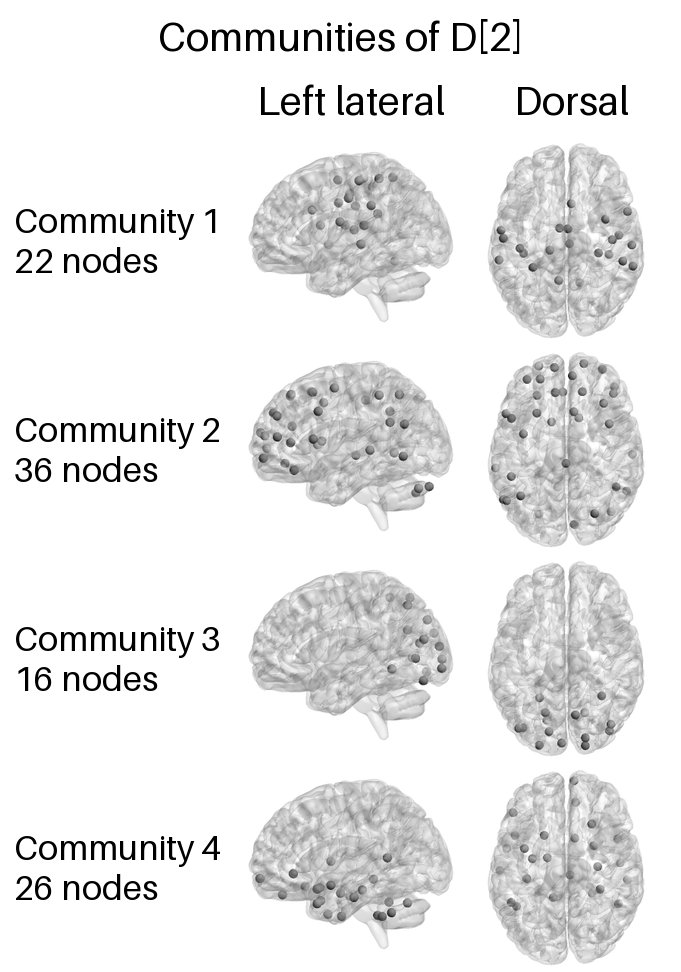

In [10]:
for k in community_orders:
    rows = [[plot_network(xyz[s], snap=False, size=VIEW_SIZE, view=v) for v in ('left', 'dorsal')]
            for s in node_sets[k]]
    show_image(montage(rows, [f'Community {c + 1}\n{len(s)} nodes' for c, s in enumerate(node_sets[k])],
                    ['Left lateral', 'Dorsal'], title=f'Communities of D[{k}]', cell_width=220))

## 5. Animations

Each animation shows every 6th timepoint (50 frames, 5 frames per second), in a left lateral and a dorsal view.

- **Order 1**: edges between nodes, from the participant-averaged correlations `R(t)` described in section 4. In every frame, the 50 node pairs with the largest `|R(t)|` (about 1% of the 4,950 pairs) are drawn: red for positive and blue for negative correlations, with diameter `4 |R(t)|` mm (htfa's default edge style draws a value `E` with diameter `|E|` mm; the values are multiplied by 4 so that the edges are visible at this image size). The nodes are drawn at a fixed size.
- **Orders 2 to 4**: node sizes. For each node, the value is the magnitude column `c_i(t)` of `X[k]` whose feeding column contains the node (section 4), averaged over participants; every node of a set gets the set's value. Within each frame, sizes are scaled linearly from 2 mm (smallest value in that frame) to 7 mm (largest), so the sizes compare nodes at one timepoint, not timepoints with each other; the plot after the animations shows the values over time. The signed columns `s_i(t)` are not drawn.

In [11]:
MOVIE_DIR = DATA_DIR / 'movies'
MOVIE_DIR.mkdir(exist_ok=True)
FRAMES = np.arange(0, T, 6)
TOP_EDGES = 50
iu = np.triu_indices(K, 1)


def render(order, draw, path):
    # draw(t, view) -> PIL image; returns the movie's path
    def frames():
        for t in FRAMES:
            yield annotate_pair(draw(t, 'left'), draw(t, 'dorsal'), ('Left lateral', 'Dorsal'),
                                caption=f'Order {order} | timepoint {t + 1} of {T}', width=560)
    start = time.time()
    write_animation(frames(), path, fps=5)
    print(f'order {order}: {len(FRAMES)} frames in {time.time() - start:.0f} s, '
          f'{path.stat().st_size / 1e6:.2f} MB')
    return path


def show(path):
    display(Video(str(path), embed=True, width=560, html_attributes='controls loop muted'))

### Order 1

In [12]:
start = time.time()
R = tc.vec2mat(tc.timecorr(data, cfun=tc.isfc, combine=tc.corrmean_combine))   # (K, K, T)
print(f'participant-averaged correlations {R.shape}: {time.time() - start:.0f} s')
pairs = np.abs(R[iu[0], iu[1], :])                                           # (4950, T)
cutoff = np.sort(pairs, axis=0)[-TOP_EDGES, :]                               # 50th largest per t
print(f'|R(t)| of the 50th strongest pair: from {cutoff.min():.3f} to {cutoff.max():.3f}')


def top_edges(t):
    E = np.where(np.abs(R[:, :, t]) >= cutoff[t], R[:, :, t], 0.0)
    np.fill_diagonal(E, 0.0)
    return E


movie1 = render(1, lambda t, view: plot_network(xyz, 4 * top_edges(t), sizes=np.ones(K), snap=False,
                                                 threshold=0.0, size=VIEW_SIZE, view=view),
                MOVIE_DIR / 'order1.mp4')
show(movie1)

participant-averaged correlations (100, 100, 300): 9 s
|R(t)| of the 50th strongest pair: from 0.154 to 0.597


order 1: 50 frames in 60 s, 1.19 MB


The per-node values of orders 2 to 4:

In [13]:
node_values = {}
for k in range(2, 5):
    sets = node_sets[k - 1]
    n_in = len(sets)
    magnitude = np.mean([x[:, :n_in] for x in X[k]], axis=0)        # (T, columns of D[k-1])
    values = np.empty((T, K))
    covered = np.zeros(K, dtype=bool)
    for col, members in enumerate(sets):
        values[:, members] = magnitude[:, [col]]
        covered[members] = True
    assert covered.all(), 'some nodes are in no feeding column'
    node_values[k] = values
    flat = np.ptp(magnitude, axis=0) == 0
    print(f'order {k}: {n_in} magnitude columns of X[{k}] (of {X[k][0].shape[1]}) -> {K} nodes; '
          f'{flat.sum()} columns constant over time (participant average)')

order 2: 100 magnitude columns of X[2] (of 200) -> 100 nodes; 0 columns constant over time (participant average)
order 3: 4 magnitude columns of X[3] (of 8) -> 100 nodes; 0 columns constant over time (participant average)
order 4: 4 magnitude columns of X[4] (of 8) -> 100 nodes; 0 columns constant over time (participant average)


### Order 2

In [14]:
movie2 = render(2, lambda t, view: plot_network(xyz, sizes=node_values[2][t], snap=False,
                                                     size=VIEW_SIZE, view=view),
                  MOVIE_DIR / 'order2.mp4')
show(movie2)

order 2: 50 frames in 58 s, 0.86 MB


### Order 3

In [15]:
movie3 = render(3, lambda t, view: plot_network(xyz, sizes=node_values[3][t], snap=False,
                                                     size=VIEW_SIZE, view=view),
                  MOVIE_DIR / 'order3.mp4')
show(movie3)

order 3: 50 frames in 59 s, 0.74 MB


### Order 4

In [16]:
movie4 = render(4, lambda t, view: plot_network(xyz, sizes=node_values[4][t], snap=False,
                                                     size=VIEW_SIZE, view=view),
                  MOVIE_DIR / 'order4.mp4')
show(movie4)

order 4: 50 frames in 59 s, 0.49 MB


### The values over time

The animations scale each frame on its own. The plot below shows the drawn values themselves: for order 1, the mean of `|R(t)|` over the 4,950 node pairs; for orders 2 to 4, the mean of the node values over the 100 nodes (each scaled by its largest value over time, so that the orders share an axis).

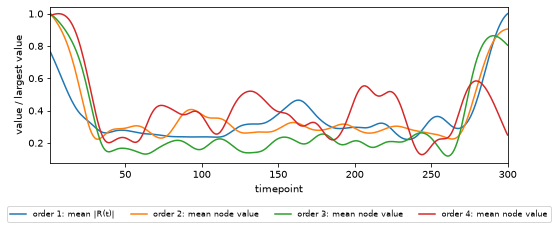

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.4))
mean_abs_r = pairs.mean(axis=0)
ax.plot(np.arange(1, T + 1), mean_abs_r / mean_abs_r.max(), label='order 1: mean |R(t)|')
for k in range(2, 5):
    m = node_values[k].mean(axis=1)
    ax.plot(np.arange(1, T + 1), m / m.max(), label=f'order {k}: mean node value')
ax.set_xlabel('timepoint')
ax.set_ylabel('value / largest value')
ax.legend(fontsize=8, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.25))
ax.set_xlim(1, T)
plt.tight_layout()
plt.show()

## Summary

- Data: the HTFA node weights of the 36 participants of the intact condition (300 timepoints each), for 100 of the 700 template nodes (section 2).
- `tc.features(data, order=4, return_info=True)` with the defaults: the feeding steps of orders 1 and 3 used the `WeightedStrength` fallback, and that of order 2 used 4 communities (section 3).
- What each animation draws, and where:
  - order 1: the participant-averaged dynamic correlations between nodes (the correlations that the PCA of `X[1]` reduces), as the 50 strongest edges of each frame;
  - order 2: for each node, the magnitude column of `X[2]` for that node's feeding feature;
  - orders 3 and 4: the magnitude columns of `X[3]` and `X[4]`, one per community of `D[2]`, each drawn on the nodes of its community.
- Not drawn: `X[1]` itself (PCA components have no location) and the signed columns of orders 2 to 4.
- The averaged values of every order are higher in the first 25 or so timepoints than in the middle of the recording, and those of orders 1 to 3 also in the last 25 or so (plot above); there, the Gaussian kernels of the analysis and feeding paths extend past the start or end of the recording. The per-frame scaling of the node sizes hides these differences in the animations.